In [ ]:


# Import statements
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
import math

import MechDesign.Helpers as HM

from MechDesign.Units.Units import m_, mm_, kg_, s_, N_, rpm_, W_, deg_, mu_m_
import MechDesign.Units.UnitMethods as UM

import MechDesign.RnM as RnM

In [699]:
B = RnM.Belt()


In [ ]:

B.Pprime = B.P*B.K_A/B.eta
B.F_t = B.Pprime / B.v   
B.v = B.E16_36_BeltSpeed()
B.m = B.E16_3_Eytelwein()

B.K_A = 1.7
B.beta_1 = 2.841
B.eta = 0.9 
B.P = 15000*W_
#B.d_w = 160*mm_
B.n = 1500*rpm_

B.F_a = UM.kgm_s2_to_N( UM.All_to_SI(B.E16_6_AxleLoad()))
t=HM.EqPrint('F_a',B.F_a)




Eq(F_a, 57.42*N_*m_*(1.91*exp(2.841*_mu) + exp(5.682*_mu) + 1.0)**0.5/(_d_w*(exp(2.841*_mu) - 1.0)))

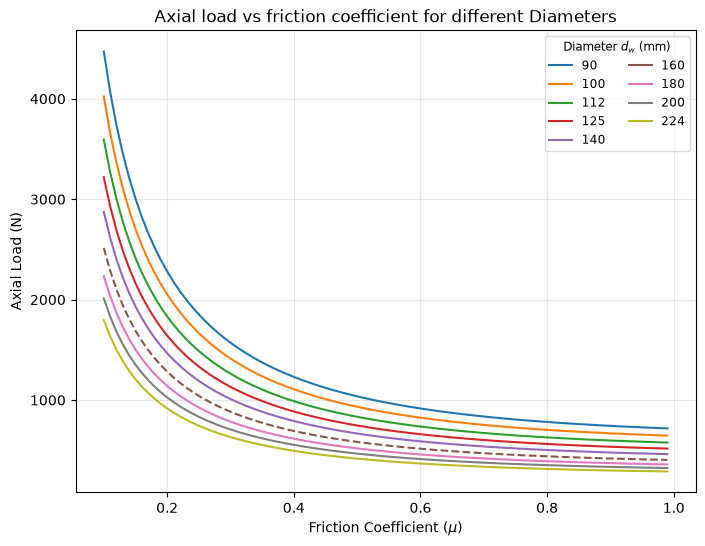

In [705]:
# 1. Convert mm to meters as pure numerical floats (divide by 1000)
diameter_mm = [90, 100, 112, 125, 140, 160, 180, 200, 224]
diameter_vals = [d / 1000.0 for d in diameter_mm]  # Pure numbers in meters

mu_vals = np.arange(0.10, 1.0, 0.01)

# Evaluate axle load
F_a_vals, A, B = HM.evaluate(B.F_a, {'d_w': diameter_vals, 'mu': mu_vals})

# 2. Convert SymPy numeric objects to a clean NumPy float array
F_a_vals = np.array(F_a_vals, dtype=float)

fig, ax = plt.subplots(figsize=(8, 6))


lines = ax.plot(mu_vals, F_a_vals.T)

ax.legend(lines, diameter_mm, title=r'Diameter $d_w$ (mm)',
          loc='upper right', ncol=2, fontsize='small', title_fontsize='small',
          framealpha=0.7)

ax.set_title('Axial load vs friction coefficient for different Diameters')
ax.set_xlabel(r'Friction Coefficient ($\mu$)')
ax.set_ylabel('Axial Load (N)')
lines[diameter_mm.index(160)].set_linestyle('--')


plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print("hi")

hi
